**First Machine Learning Model**

**Goal:**

Predict whether a Titanic passenger survived (`Survived` = 1) using Logistic Regression.

This continues my Task 1 EDA. One change from Task 1: there I filled missing `Age` values using the whole dataset. For modelling, that would leak information from the test set into training, so here all cleaning happens inside a Pipeline that is fit on the training set only.

## 1. Import libraries and load data
I import the scikit-learn tools I need and load the same Titanic dataset I used in Task 1. I also drop duplicate rows.

In [9]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url).drop_duplicates()
print(df.shape)

(891, 12)


## 2. Choose features and target
The target is `Survived`. I use `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`, `Sex` and `Embarked` as features. I leave out `PassengerId`, `Name` and `Ticket` (identifiers, not useful for prediction) and `Cabin` (about 77% missing, as found in Task 1). `Survived` is never part of `X`, otherwise the model would be cheating.

In [10]:
features_num = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
features_cat = ["Sex", "Embarked"]
X = df[features_num + features_cat]
y = df["Survived"]

## 3. Train/test split (before any cleaning)
I split the data 80/20 first, using `stratify=y` so both sets have the same survived/died ratio. The test set is kept aside and only used at the end to check how the model does on passengers it has never seen.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (712, 7) Test: (179, 7)


## 4. Build the pipeline and train
Missing-value filling, scaling and encoding are inside a Pipeline, so the median age, the average fare and the most common port are learned from the **training data only** and then applied to the test data. This avoids data leakage.

- Numeric columns: fill missing values with the median, then scale.
- Categorical columns (`Sex`, `Embarked`): fill missing values with the most common value, then one-hot encode.
- Model: Logistic Regression, which predicts the probability that a passenger survived.

In [12]:
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocess = ColumnTransformer([("num", num_pipe, features_num),
                                ("cat", cat_pipe, features_cat)])

model = Pipeline([("prep", preprocess),
                  ("clf", LogisticRegression(max_iter=1000, random_state=42))])
model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

## 5. Evaluate on the test set
I compare my model with a baseline that always predicts "died". If my model can't beat that, it hasn't learned anything useful. I also run 5-fold cross-validation on the training set to check that the score is stable and not just luck from one split.

In [13]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

def scores(m):
    p = m.predict(X_test)
    return {"Accuracy": accuracy_score(y_test, p),
            "Precision": precision_score(y_test, p, zero_division=0),
            "Recall": recall_score(y_test, p),
            "F1": f1_score(y_test, p)}

results = pd.DataFrame({"Always predict 'died'": scores(baseline),
                        "Logistic Regression": scores(model)}).T.round(3)
print(results)

cv = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
print("5-fold CV accuracy: %.3f ± %.3f" % (cv.mean(), cv.std()))

                       Accuracy  Precision  Recall     F1
Always predict 'died'     0.615      0.000   0.000  0.000
Logistic Regression       0.804      0.793   0.667  0.724
5-fold CV accuracy: 0.796 ± 0.019


### What the metrics mean
- **Accuracy:** the share of all passengers predicted correctly. It can be misleading when one class is bigger than the other, which is why I compare against the baseline.
- **Precision:** when the model says "survived", how often it is right.
- **Recall:** of the passengers who really survived, how many the model found.
- **F1:** a single score that balances precision and recall; it is low if either one is low.

**My result:** the model reaches about 80% accuracy versus about 62% for the baseline. Its precision is higher than its recall, so it is usually right when it predicts survival, but it misses some real survivors.

## 6. Confusion matrix
This shows exactly where the model is right and wrong: correct "died" and "survived" predictions on the diagonal, and the mistakes (false alarms and missed survivors) off the diagonal.

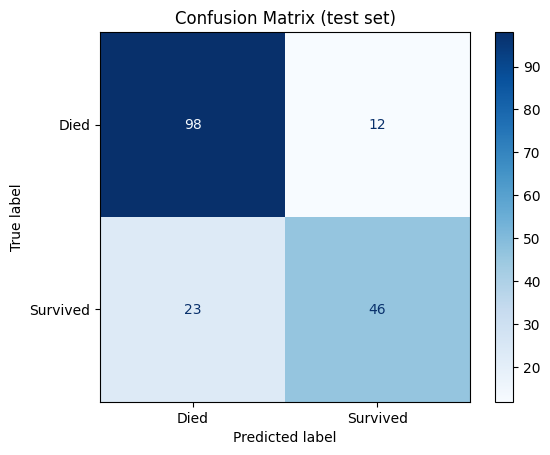

In [14]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test,
    display_labels=["Died", "Survived"], cmap="Blues")
plt.title("Confusion Matrix (test set)")
plt.show()

## 7. Which features matter most?
These are the Logistic Regression coefficients. Positive values push the prediction towards "survived", negative values towards "died". The model learned the same pattern I saw in my Task 1 EDA: being female and travelling in a higher class (lower `Pclass` number) increases the chance of survival.

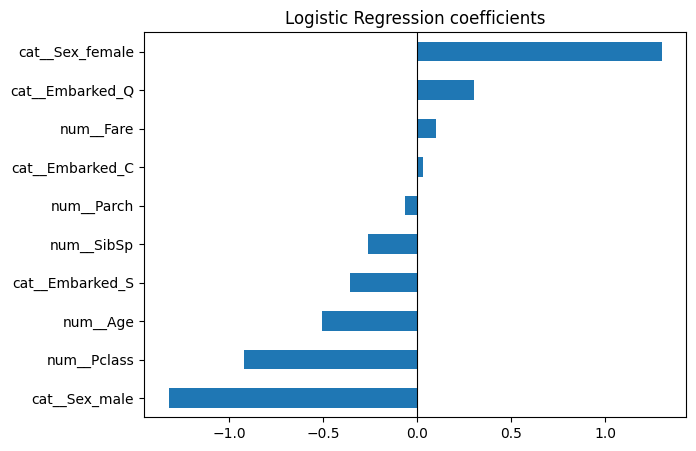

In [15]:
names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=names).sort_values()
coefs.plot.barh(figsize=(7, 5), title="Logistic Regression coefficients")
plt.axvline(0, color="k", lw=0.8)
plt.show()

## 8. Save the model
I save the whole pipeline (preprocessing and model) with joblib, so when it is loaded again it handles raw passenger data automatically. I reload it and check that it gives the same accuracy, to be sure the file works.

In [16]:
joblib.dump(model, "titanic_logreg_model.joblib")

loaded = joblib.load("titanic_logreg_model.joblib")
print("Reloaded accuracy:", round(accuracy_score(y_test, loaded.predict(X_test)), 3))

from google.colab import files
files.download("titanic_logreg_model.joblib")

Reloaded accuracy: 0.804


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>